# E4 — Hệ thống sẵn sàng, chịu lỗi và chịu tải đến đâu?

**Notebook học theo từng bước** của giai đoạn 6. Yêu cầu của GVHD: *"đánh giá tính sẵn sàng của hệ thống, khả năng chịu lỗi, chịu tải"*. Báo cáo đi kèm: [`../E4-san-sang-chiu-loi-chiu-tai.md`](../E4-san-sang-chiu-loi-chiu-tai.md).

**Cách dùng trong VS Code:** chọn kernel `.venv`, chạy từng ô bằng **Shift + Enter**. Mỗi phần có: **Đang làm gì** → **Đoán trước** → ô code → **Đọc kết quả**. Notebook chỉ đọc các file đã lưu trong `outputs/e4/`, **không gọi vào cụm**.

| Bước nhỏ | Nội dung | Trạng thái |
| --- | --- | --- |
| **6.1** | Khảo sát: hệ thống đang được bảo vệ thế nào, điểm hỏng đơn lẻ | Xong (xem báo cáo, mục 3) |
| **6.2** | Đọc lại lịch sử: phát hành, rollback, 7 ngày sẵn sàng | Xong |
| 6.3 | Thêm số đo request vào hệ thống (Prometheus/Grafana) — phần áp dụng, xem báo cáo mục 4.2 | Đã viết, chờ phát hành |
| 6.4 | Kiểm tải | Chưa |
| 6.5 | Kiểm chịu lỗi (xóa 1 pod) | Chưa |
| 6.6 | Báo cáo | Chưa |

In [1]:
from pathlib import Path
import json

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "experiments" / "outputs" / "e4").is_dir())
DATA, FIG = ROOT / "experiments" / "outputs" / "e4", ROOT / "experiments" / "figures"
pd.set_option("display.precision", 0)
BLUE, ORANGE, INK, MUTED, GRID = "#257de0", "#f47230", "#191919", "#666666", "#e6e6e6"   # bảng màu đã kiểm (dataviz)
VN = "Asia/Ho_Chi_Minh"
runs = pd.read_csv(DATA / "delivery_runs.csv", parse_dates=["created_at"])
print("Số lượt CI/CD đọc được:", len(runs), "| từ", runs.created_at.min().tz_convert(VN).date(), "đến", runs.created_at.max().tz_convert(VN).date())

Số lượt CI/CD đọc được: 86 | từ 2026-11-10 đến 2026-11-27


---
## Bước 6.2 — Nhìn lại quá khứ: hệ thống đã thật sự sẵn sàng đến đâu?

**Đang làm gì.** Trước khi tự tạo tình huống (kiểm tải, xóa pod), hãy xem **những gì đã xảy ra thật**. Hệ thống có hai nguồn ghi sẵn:

1. **Báo cáo CI/CD** (`delivery-metrics`): mỗi lượt chạy pipeline tự lưu thời gian từng job, từng pha phát hành, kết quả (triển khai thành công, không có gì đổi, rollback). GitHub giữ 30 ngày → còn **86 lượt** từ 10/11 đến 27/11. Script `scripts/e4_delivery_table.py` gom thành `delivery_runs.csv`.
2. **Prometheus** (giữ 7 ngày): cứ 10–30 giây ghi một lần **mỗi pod có đang "sẵn sàng" (Ready) không**. Script `scripts/e4_prometheus_availability.py` đọc ra `availability_7d.json` và dòng thời gian `api_ready_timeline.csv`.

**Một khái niệm cần nắm — "sẵn sàng" ở đây nghĩa là gì?** Kubernetes hỏi mỗi pod API `/health/serving-ready` mỗi 5 giây; trả lời đúng thì pod được nhận request. Đếm số pod Ready theo thời gian là cách **gần đúng** để biết dịch vụ có người phục vụ hay không. Nó **chưa phải** "mọi request đều thành công" — phần đó cần số đo request (bước 6.3).

### 6.2a — Đã phát hành bao nhiêu lần, mỗi lần mất bao lâu?

**Đoán trước.** Mỗi lần đẩy mã lên `master`, pipeline chạy kiểm thử → đóng gói image → triển khai blue/green → kiểm tra. Bạn đoán từ lúc đẩy mã tới lúc bản mới chạy thật mất bao lâu: 5 phút, 20 phút hay 1 giờ? Và bao nhiêu lần trong số đó phải rollback?

In [2]:
outcome = runs.backend.map({"verified_deploy": "Triển khai thành công", "rolled_back": "Lỗi → tự rollback",
                            "no_op": "Không có gì đổi (bỏ qua)", "not_observed": "Không triển khai (PR, chỉ kiểm thử…)"})
display(outcome.value_counts().rename("Số lượt").to_frame())

dep = runs[runs.backend == "verified_deploy"].copy()
def stats(series):
    s = series.dropna() / 60
    return pd.Series({"n": len(s), "trung bình": s.mean(), "độ lệch": s.std(), "nhỏ nhất": s.min(),
                      "trung vị": s.median(), "lớn nhất": s.max()})
pd.set_option("display.precision", 1)
table = pd.DataFrame({
    "Đẩy mã → bản mới chạy thật (phút)": stats(dep.backend_commit_to_verify),
    "Riêng phần triển khai trên cụm (phút)": stats(dep.filter(like="phase_").sum(axis=1, min_count=1)),
    "Kiểm thử CI của lượt đó (phút)": stats(dep.ci_execution_span),
}).T
table

,Số lượt
backend,
"Không triển khai (PR, chỉ kiểm thử…)",58
Triển khai thành công,21
Không có gì đổi (bỏ qua),5
Lỗi → tự rollback,2


,n,trung bình,độ lệch,nhỏ nhất,trung vị,lớn nhất
Đẩy mã → bản mới chạy thật (phút),21.0,24.5,20.3,14.2,17.8,106.1
Riêng phần triển khai trên cụm (phút),21.0,9.7,1.8,6.8,9.5,13.7
Kiểm thử CI của lượt đó (phút),21.0,8.2,8.0,3.5,5.8,32.8


**Đọc kết quả.**
- Trong 18 ngày có **23 lần triển khai thật** lên cụm: **21 thành công**, **2 lỗi và tự rollback** (cùng ngày 19/11). 5 lượt khác pipeline thấy không có gì đổi nên **không đụng vào cụm** — đúng thiết kế.
- **Đẩy mã → bản mới chạy thật: trung vị ≈ 18 phút** (nhỏ nhất ≈ 14; một nửa số lần nằm trong 16–21 phút). Trung bình bị kéo lên ≈ 24 phút bởi 2 lượt đặc biệt: lượt đổi runtime ngày 10/11 (≈ 106 phút, có thể gồm thời gian chờ duyệt) và lượt 27/11 (≈ 38 phút, gồm cả thời gian chờ dọn đĩa node rồi chạy lại). Vì vậy với số liệu lệch như này, **trung vị** đại diện tốt hơn trung bình.
- Riêng phần triển khai trên cụm ≈ **9,7 ± 1,8 phút**, rất ổn định giữa các lần.
- Tỉ lệ phát hành lỗi = 2 / 23 ≈ **9%**. Cả hai lần hệ thống tự quay về bản cũ (xem 6.2c).

### 6.2b — Trong ≈ 10 phút triển khai, người dùng có bị gián đoạn lúc nào?

**Đoán trước.** Triển khai gồm nhiều pha. Nếu phải chọn **một** pha mà người dùng "cảm thấy" được, bạn chọn pha nào? Nó dài bao lâu?

,trung bình (giây),độ lệch,số lần có pha này
Lập kế hoạch,41.0,15.0,21
"Kiểm điều kiện (đĩa, training đang chạy…)",50.0,15.0,21
Dựng API bản mới (song song bản cũ),110.0,44.0,21
Dựng worker bản mới,39.0,21.0,21
Cập nhật Airflow,37.0,10.0,2
CHUYỂN người dùng sang bản mới,19.0,7.0,21
Kiểm tra bản mới sau khi chuyển,65.0,16.0,21
Bản cũ xả request rồi tắt,232.0,61.0,21
Mở lại hàng chờ training,22.0,6.0,21


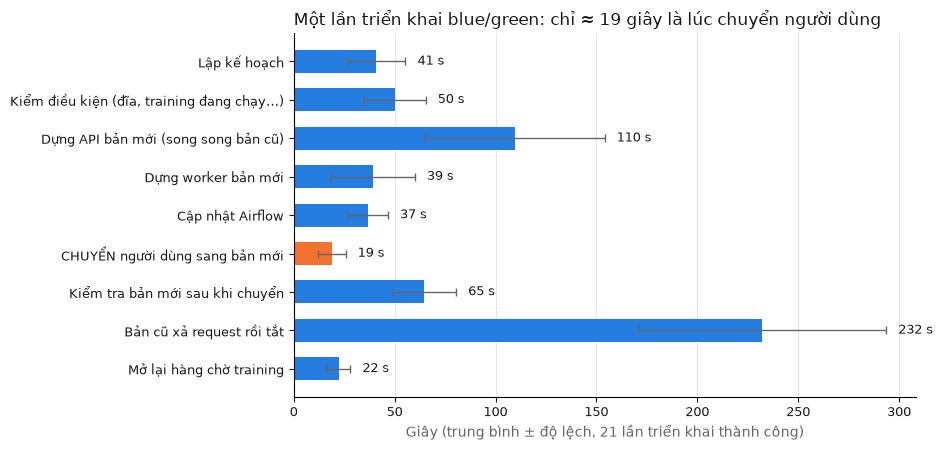

In [3]:
PHASE_VN = {"plan": "Lập kế hoạch", "admission": "Kiểm điều kiện (đĩa, training đang chạy…)",
            "stage_api": "Dựng API bản mới (song song bản cũ)", "stage_workers": "Dựng worker bản mới",
            "update_airflow": "Cập nhật Airflow", "promote": "CHUYỂN người dùng sang bản mới",
            "verify_promoted": "Kiểm tra bản mới sau khi chuyển", "retire": "Bản cũ xả request rồi tắt",
            "release_admission": "Mở lại hàng chờ training"}
phases = dep[["phase_" + k for k in PHASE_VN]].rename(columns=lambda c: PHASE_VN[c[6:]])
summary = pd.DataFrame({"trung bình (giây)": phases.mean(), "độ lệch": phases.std(), "số lần có pha này": phases.count()})
display(summary.round(0))

fig, ax = plt.subplots(figsize=(9.5, 4.6))
order = summary.index[::-1]
colors = [ORANGE if "CHUYỂN" in name else BLUE for name in order]
ax.barh(order, summary.loc[order, "trung bình (giây)"], xerr=summary.loc[order, "độ lệch"], color=colors,
        height=0.6, error_kw={"ecolor": MUTED, "elinewidth": 1, "capsize": 3})
for y, name in enumerate(order):
    ax.text(summary.loc[name, "trung bình (giây)"] + float(summary.loc[name, "độ lệch"]) + 6, y,
            f"{summary.loc[name, 'trung bình (giây)']:.0f} s", va="center", color=INK, fontsize=9)
ax.set_xlabel("Giây (trung bình ± độ lệch, 21 lần triển khai thành công)", color=MUTED)
ax.set_title("Một lần triển khai blue/green: chỉ ≈ 19 giây là lúc chuyển người dùng", loc="left", color=INK, fontsize=12)
ax.grid(axis="x", color=GRID); ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.tick_params(colors=INK, labelsize=9)
fig.tight_layout(); fig.savefig(FIG / "E4-1-deploy-phases.png", dpi=150); plt.show()

**Đọc kết quả.**
- Pha người dùng "chạm" tới là **CHUYỂN sang bản mới** (`promote`): chỉ **≈ 19 ± 7 giây** (10–31 giây). Đó là lúc Service đổi từ bản cũ sang bản mới.
- Các pha **trước** khi chuyển (≈ 4 phút: kiểm điều kiện, dựng API và worker bản mới) chạy **song song** với bản cũ đang phục vụ — người dùng không thấy gì.
- Pha **dài nhất** là "bản cũ xả request rồi tắt" (≈ 4 phút): bản cũ được chờ làm xong việc dở **sau khi** người dùng đã sang bản mới. Dài nhưng **vô hại**, chính là cái giá của "không cắt ngang request".
- Câu hỏi còn mở: trong ≈ 19 giây chuyển, có request nào rớt không? Số pod Ready không trả lời được (6.2c); cần số đo request — sẽ thử ở 6.5 sau khi có bước 6.3.

### 6.2c — 7 ngày qua, có lúc nào API không có ai phục vụ?

**Đoán trước.** Trong 7 ngày gần nhất có 9 lần triển khai. Mỗi lần, bản cũ bị tắt. Bạn đoán số pod API sẵn sàng có lúc nào **rơi xuống 1** hay **xuống 0** không?

,7 ngày
Số phút có dữ liệu,10080.0
% thời gian có ≥ 1 pod API sẵn sàng,100.0
% thời gian có đủ ≥ 2 pod API,100.0
Số pod API sẵn sàng thấp nhất,2.0
Số phút chỉ còn < 2 pod,0.0
% thời gian postgres sẵn sàng,100.0
% thời gian minio sẵn sàng,100.0
% thời gian mlflow sẵn sàng,100.0
% thời gian airflow-scheduler sẵn sàng,100.0
% thời gian airflow-webserver sẵn sàng,100.0


Số phút theo số pod API sẵn sàng: {2: 10046, 3: 11, 4: 24}


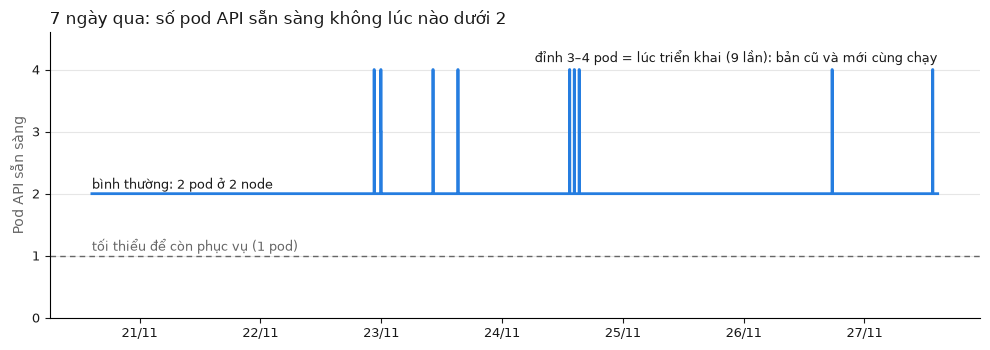

In [4]:
avail = json.loads((DATA / "availability_7d.json").read_text(encoding="utf-8"))
line = pd.read_csv(DATA / "api_ready_timeline.csv", parse_dates=["time_utc"])
line["time"] = line.time_utc.dt.tz_convert(VN)
show = {"Số phút có dữ liệu": avail["minutes_with_data"],
        "% thời gian có ≥ 1 pod API sẵn sàng": 100 * avail["api_ready_ge1_share"],
        "% thời gian có đủ ≥ 2 pod API": 100 * avail["api_ready_ge2_share"],
        "Số pod API sẵn sàng thấp nhất": avail["api_ready_min"],
        "Số phút chỉ còn < 2 pod": avail["api_minutes_below2"]}
show.update({f"% thời gian {k} sẵn sàng": 100 * v["ready_share"] for k, v in avail["components"].items()})
show.update({f"% thời gian {k} Ready": 100 * v for k, v in avail["nodes"].items()})
display(pd.Series(show).round(2).rename("7 ngày").to_frame())
print("Số phút theo số pod API sẵn sàng:", line.api_ready_pods.value_counts().sort_index().to_dict())

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.step(line.time, line.api_ready_pods, where="post", color=BLUE, linewidth=2)
ax.axhline(1, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.text(line.time.iloc[0], 1.08, "tối thiểu để còn phục vụ (1 pod)", color=MUTED, fontsize=9)
ax.text(line.time.iloc[0], 2.08, "bình thường: 2 pod ở 2 node", color=INK, fontsize=9)
deploys = dep[dep.created_at >= line.time_utc.min()]
ax.text(line.time.iloc[-1], 4.12, f"đỉnh 3–4 pod = lúc triển khai ({len(deploys)} lần): bản cũ và mới cùng chạy",
        color=INK, fontsize=9, ha="right")
ax.set_ylim(0, 4.6); ax.set_yticks([0, 1, 2, 3, 4])
ax.set_ylabel("Pod API sẵn sàng", color=MUTED)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m", tz=line.time.dt.tz))
ax.set_title("7 ngày qua: số pod API sẵn sàng không lúc nào dưới 2", loc="left", color=INK, fontsize=12)
ax.grid(axis="y", color=GRID); ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.tick_params(colors=INK, labelsize=9)
fig.tight_layout(); fig.savefig(FIG / "E4-2-api-ready-7d.png", dpi=150); plt.show()

**Đọc kết quả.**
- Trong **10.080 phút** (7 ngày), số pod API sẵn sàng **không lúc nào dưới 2** — kể cả trong 9 lần triển khai. Kiểm lại với mẫu dày hơn (mỗi 15 giây) cho cùng kết quả (min = 2).
- Lúc triển khai, số pod **tăng** lên 3–4 (≈ 35 phút cộng dồn trong 7 ngày) vì blue/green dựng bản mới **trước** rồi mới tắt bản cũ — đúng cách để không gián đoạn.
- PostgreSQL, MinIO, MLflow, Airflow và cả 3 node: **100%** thời gian sẵn sàng trong 7 ngày; không pod nào khởi động lại.
- **Giới hạn:** 7 ngày là toàn bộ dữ liệu Prometheus giữ được; đây là tuần **ít sự cố**, và là số pod Ready chứ chưa phải tỉ lệ request thành công.

### 6.2d — Khi phát hành lỗi hoặc cả cụm khởi động lại thì sao?

**Đoán trước.** Hai lần rollback ngày 19/11: bạn đoán hệ thống mất bao lâu để quay về trạng thái an toàn?

In [5]:
rb = runs[runs.backend == "rolled_back"][["run_id", "attempt", "created_at", "failed_release_to_verified_rollback"]].copy()
rb["created_at"] = rb.created_at.dt.tz_convert(VN).dt.strftime("%d/%m %H:%M")
rb["lỗi → rollback xong (phút)"] = rb.pop("failed_release_to_verified_rollback") / 60
display(rb.round(1))
print("Lần khởi động node gần nhất (giờ VN):",
      {k: pd.Timestamp(v).tz_convert(VN).strftime("%d/%m %H:%M:%S") for k, v in avail["node_boot_utc"].items()})

,run_id,attempt,created_at,lỗi → rollback xong (phút)
43,44445611558,1,19/11 09:36,7.7
51,44540726226,2,19/11 22:08,5.8


Lần khởi động node gần nhất (giờ VN): {'mlops-node-01': '08/11 12:32:28', 'mlops-node-02': '08/11 12:33:26', 'mlops-node-03': '08/11 12:33:51'}


**Đọc kết quả.**
- Hai lần phát hành lỗi (19/11) được **tự rollback trong ≈ 5,8 và ≈ 7,7 phút** (từ lúc phát hiện lỗi tới lúc kiểm xong bản cũ). Nhật ký ghi cả hai lần là "rollback an toàn": lỗi xảy ra ở pha đọc Kubernetes/kết thúc, dịch vụ vẫn chạy. Hai lần này nằm ngoài 7 ngày Prometheus nên không có số pod Ready để đối chiếu.
- Có thêm các lần pipeline **dừng trước khi đụng vào cụm** (19/11: lệnh trong pod quá thời gian; 27/11: node-02 thiếu đĩa). Các lần này không có trong mẫu "triển khai", nhưng đều **không làm gián đoạn** — hệ thống giữ nguyên bản cũ.
- Cả 3 node khởi động lại trong **≈ 1,5 phút, 12:32–12:34 ngày 08/11**. Đây là một **sự cố**: cloud của trường gặp vấn đề, các node lỗi, người dùng reboot cả 3 node (người dùng xác nhận 27/11). Sau reboot, Kubernetes **tự** đưa dịch vụ lên lại — PostgreSQL/MinIO chạy lại lúc 12:35:30, ≈ 3 phút sau node đầu tiên, không ai thao tác pod. Thời lượng gián đoạn thật (từ lúc cloud gặp sự cố) **không đo được** vì chưa có đầu dò từ bên ngoài — một lý do nữa cho bước 6.3. Từ đó tới 27/11 cụm chạy liên tục **≈ 19 ngày**, không node nào khởi động lại.

---
## Kết luận bước 6.2

| Câu hỏi | Trả lời từ dữ liệu thật |
| --- | --- |
| Phát hành có gây gián đoạn không? | Số pod API sẵn sàng **không dưới 2** trong 9 lần triển khai của 7 ngày qua; pha chuyển chỉ ≈ 19 giây |
| Phát hành mất bao lâu? | Đẩy mã → chạy thật: trung vị ≈ 18 phút; phần trên cụm ≈ 9,7 ± 1,8 phút |
| Phát hành lỗi thường xuyên không, xử lý ra sao? | 2/23 ≈ 9%; tự rollback trong 6–8 phút, dịch vụ vẫn chạy |
| 7 ngày qua sẵn sàng bao nhiêu? | 100% theo số pod Ready (API, DB, kho file, node) |

**Bài học về phương pháp.**
1. **Đọc dữ liệu có sẵn trước khi tạo thí nghiệm mới** — rẻ, không rủi ro, và là "điều kiện thật".
2. **Nói rõ mình đang đo cái gì.** "Pod Ready 100%" ≠ "uptime 100%": nó chỉ nói luôn có pod sẵn sàng nhận việc. Người viết báo cáo phải ghi đúng tên chỉ số.
3. **Dữ liệu lệch thì dùng trung vị**, và tách riêng các lượt bất thường thay vì để chúng kéo trung bình.
4. **Độ phân giải lấy mẫu quyết định cái thấy được**: một khoảng hở 10 giây có thể lọt giữa hai lần ghi 30 giây. Vì vậy cần thêm số đo ở mức request (6.3).